In [1]:
# run once; skip any you already have
%pip install numpy pandas scipy scikit-learn joblib matplotlib pyarrow

import os

# >>> EDIT THIS <<<
# Folder that directly contains your 3 test folders (1st_test, 2nd_test, 3rd_test/4th_test)
DATA_ROOT = r'bearings'      # Windows: use r'...' so backslashes work
# DATA_ROOT = '/Users/you/Bearings'       # macOS / Linux

# Where cached features and the trained model get saved
OUT_DIR = os.path.join(os.getcwd(), 'bearings_out')
os.makedirs(OUT_DIR, exist_ok=True)

print(os.listdir(DATA_ROOT))   # should show your 3 test folders

Note: you may need to restart the kernel to use updated packages.
['1st_test', '2nd_test', '3rd_test', 'Readme Document for IMS Bearing Data.pdf']


In [2]:
%matplotlib inline
import glob, joblib
from datetime import datetime
import numpy as np, pandas as pd
from scipy import signal, stats
from joblib import Parallel, delayed
from sklearn.ensemble import HistGradientBoostingRegressor
import matplotlib.pyplot as plt

FS = 20_000
# folder name -> {failed bearing: [0-indexed channel columns]}
RUNS = {
    '1st_test': {'b3': [4, 5], 'b4': [6, 7]},
    '2nd_test': {'b1': [0]},
    '3rd_test': {'b3': [2]},      # rename to '4th_test' if that's what your folder is called
}
FAULT_HZ = {'BPFO': 236.4, 'BPFI': 296.9, 'BSF': 139.9, 'FTF': 14.8}
BASELINE_FRAC = 0.10
TARGET = 'pw'    # 'pw' = flat until degradation onset, then linear to 0; 'lin' = linear all the way

In [3]:
for t in RUNS:
    files = sorted(f for f in glob.glob(f'{DATA_ROOT}/{t}/**/*', recursive=True)
                   if os.path.isfile(f) and os.path.basename(f).count('.') == 5)
    print(t, len(files), 'files | first:', os.path.basename(files[0]), '| last:', os.path.basename(files[-1]))

sample = pd.read_csv(files[0], sep=r'\s+', header=None)
print(sample.shape)      # expect (20480, 4) or (20480, 8)
sample.head()

1st_test 2156 files | first: 2003.10.22.12.06.24 | last: 2003.11.25.23.39.56
2nd_test 984 files | first: 2004.02.12.10.32.39 | last: 2004.02.19.06.22.39
3rd_test 3371 files | first: 2004.03.04.09.27.46 | last: 2004.03.28.06.31.57
(20480, 4)


,0,1,2,3
0,0.034,0.264,0.039,-0.046
1,0.103,0.083,-0.061,-0.012
2,0.095,-0.039,-0.007,0.039
3,0.000,0.110,0.022,-0.002
4,0.005,0.154,-0.127,-0.020


In [4]:
_SOS_ENV = signal.butter(4, [2000, 9000], btype='bandpass', fs=FS, output='sos')

def time_feats(x):
    rms = np.sqrt(np.mean(x**2)); peak = np.max(np.abs(x)); mabs = np.mean(np.abs(x))
    return {'mean': x.mean(), 'std': x.std(), 'rms': rms, 'peak': peak, 'p2p': np.ptp(x),
            'skew': stats.skew(x), 'kurt': stats.kurtosis(x, fisher=False),
            'crest': peak/rms, 'shape': rms/mabs, 'impulse': peak/mabs,
            'margin': peak/(np.mean(np.sqrt(np.abs(x)))**2)}

def band_peak(f, mag, f0, width=3.0, harmonics=(1, 2, 3)):
    out = 0.0
    for h in harmonics:
        m = (f > h*f0 - width) & (f < h*f0 + width)
        if m.any(): out += mag[m].max()
    return out

def freq_feats(x):
    x = x - x.mean(); n = len(x); win = np.hanning(n)
    mag = np.abs(np.fft.rfft(x*win))/n; f = np.fft.rfftfreq(n, 1/FS)
    d = {}
    edges = np.linspace(0, 10_000, 9)
    for i in range(8):
        m = (f >= edges[i]) & (f < edges[i+1]); d[f'band{i}'] = np.sum(mag[m]**2)
    p = mag**2
    d['centroid'] = np.sum(f*p)/np.sum(p)
    d['spec_std'] = np.sqrt(np.sum(((f-d['centroid'])**2)*p)/np.sum(p))
    for k, hz in FAULT_HZ.items(): d[f'raw_{k}'] = band_peak(f, mag, hz)
    env = np.abs(signal.hilbert(signal.sosfiltfilt(_SOS_ENV, x))); env -= env.mean()
    emag = np.abs(np.fft.rfft(env*win))/n
    for k, hz in FAULT_HZ.items(): d[f'env_{k}'] = band_peak(f, emag, hz)
    return d

def file_features(path, runs):
    data = pd.read_csv(path, sep=r'\s+', header=None).values
    out = {}
    for b, cols in runs.items():
        per_ch = [{**time_feats(data[:, c].astype(float)), **freq_feats(data[:, c].astype(float))} for c in cols]
        out[b] = {k: float(np.mean([d[k] for d in per_ch])) for k in per_ch[0]}
    return out

In [5]:
CACHE = f'{OUT_DIR}/features_raw.pkl'

if os.path.exists(CACHE):
    raw = pd.read_pickle(CACHE); print('loaded cache', raw.shape)
else:
    rows = []
    for test, runs in RUNS.items():
        files = sorted(f for f in glob.glob(f'{DATA_ROOT}/{test}/**/*', recursive=True)
                       if os.path.isfile(f) and os.path.basename(f).count('.') == 5)
        res = Parallel(n_jobs=-1, verbose=5)(delayed(file_features)(f, runs) for f in files)
        for f, r in zip(files, res):
            ts = datetime.strptime(os.path.basename(f), '%Y.%m.%d.%H.%M.%S')
            for b, d in r.items():
                rows.append({'test': test, 'bearing': b, 'run': f'{test}_{b}', 'timestamp': ts, **d})
    raw = pd.DataFrame(rows).sort_values(['run', 'timestamp']).reset_index(drop=True)
    raw.to_pickle(CACHE); print('saved', raw.shape)

raw.groupby('run').size()

loaded cache (8667, 33)


run
1st_test_b3    2156
1st_test_b4    2156
2nd_test_b1     984
3rd_test_b3    3371
dtype: int64

In [6]:
def add_labels(df):
    parts = []
    for run, g in df.groupby('run', sort=False):
        g = g.sort_values('timestamp').copy()
        dt = g['timestamp'].diff().dt.total_seconds().fillna(0).clip(upper=600)  # overnight gaps -> 10 min
        g['t_hours'] = dt.cumsum()/3600
        T = g['t_hours'].iloc[-1]
        g['rul_hours'] = T - g['t_hours']
        g['rul_lin'] = g['rul_hours']/T
        parts.append(g)
    return pd.concat(parts).reset_index(drop=True)

lab = add_labels(raw)
lab.groupby('run')['t_hours'].max().rename('life_hours')

run
1st_test_b3    345.265556
1st_test_b4    345.265556
2nd_test_b1    163.833333
3rd_test_b3    561.367500
Name: life_hours, dtype: float64

In [7]:
CORE = (['rms','kurt','p2p','crest','std','skew','impulse','margin','centroid','spec_std']
        + [f'band{i}' for i in range(8)]
        + [f'raw_{k}' for k in FAULT_HZ] + [f'env_{k}' for k in FAULT_HZ])

def build_features(df):
    parts = []
    for run, g in df.groupby('run', sort=False):
        g = g.sort_values('timestamp').copy()
        nb = max(10, int(BASELINE_FRAC*len(g))); eps = 1e-12
        feats = pd.DataFrame(index=g.index)
        for c in CORE:
            base = g[c].iloc[:nb]
            if (g[c] > 0).all(): z = np.log((g[c]+eps)/(base.median()+eps))
            else:                z = (g[c]-base.median())/(base.std()+eps)
            z = z.rolling(5, min_periods=1).median().ewm(span=10, adjust=False).mean()
            feats[c] = z
            feats[c+'_slope'] = z.diff(12).fillna(0)
        hi = feats['rms']
        thr = hi.iloc[:nb].mean() + 3*hi.iloc[:nb].std() + 0.05
        above = (hi > thr).astype(int).rolling(6).sum() >= 6
        t_on = g.loc[above.idxmax(), 't_hours'] if above.any() else 0.0
        T = g['t_hours'].iloc[-1]
        g['onset_hours'] = t_on
        g['rul_pw'] = np.clip(g['rul_hours']/max(T - t_on, 1e-6), 0, 1)
        g['target'] = g['rul_pw'] if TARGET == 'pw' else g['rul_lin']
        parts.append(pd.concat([g[['run','test','bearing','timestamp','t_hours','rul_hours','rul_lin','rul_pw','target','onset_hours']], feats], axis=1))
    return pd.concat(parts).reset_index(drop=True)

feat = build_features(lab)
X_cols = [c for c in feat.columns if c in CORE or c.endswith('_slope')]
print(len(X_cols), 'features')
feat.groupby('run')[['t_hours', 'onset_hours']].max()

52 features


,t_hours,onset_hours
run,,
1st_test_b3,345.265556,340.489167
1st_test_b4,345.265556,258.322778
2nd_test_b1,163.833333,92.333333
3rd_test_b3,561.367500,0.000000


threshold: 0.123 | max smoothed rms: 0.064 | NaNs: 0


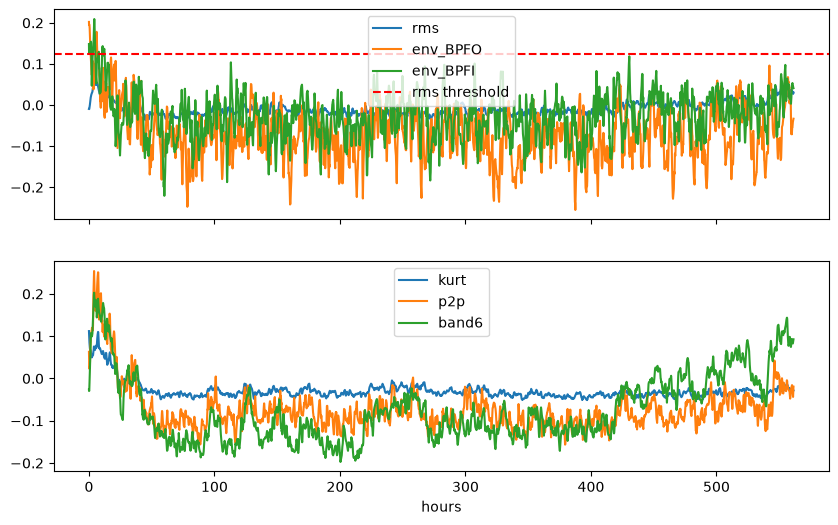

In [8]:
g = feat[feat.run == '3rd_test_b3']          # use the run name shown in your table
nb = max(10, int(BASELINE_FRAC * len(g)))
hi = g['rms']
thr = hi.iloc[:nb].mean() + 3*hi.iloc[:nb].std() + 0.05
print('threshold:', round(thr, 3), '| max smoothed rms:', round(hi.max(), 3), '| NaNs:', hi.isna().sum())

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for c in ['rms', 'env_BPFO', 'env_BPFI']:
    ax[0].plot(g['t_hours'], g[c], label=c)
for c in ['kurt', 'p2p', 'band6']:
    ax[1].plot(g['t_hours'], g[c], label=c)
ax[0].axhline(thr, color='r', ls='--', label='rms threshold')
ax[0].legend(); ax[1].legend(); ax[1].set_xlabel('hours')
plt.show()

In [9]:
CORE = (['rms','kurt','p2p','crest','std','skew','impulse','margin','centroid','spec_std']
        + [f'band{i}' for i in range(8)]
        + [f'raw_{k}' for k in FAULT_HZ] + [f'env_{k}' for k in FAULT_HZ])

ONSET_INDICATORS = ['rms', 'kurt', 'env_BPFO', 'env_BPFI', 'env_BSF', 'band5', 'band6', 'band7']
K_SIGMA, MARGIN, SUSTAIN = 4, 0.1, 6
BASE_START_H, BASE_LEN_H = 40, 30      # healthy reference = hours 40 to 70

ONSET_OVERRIDE_HOURS = {
    '1st_test_b3': 292.0,
    '1st_test_b4': 250.0,
    '2nd_test_b1': 117.0,
    '3rd_test_b3': 430.0,
}

def detect_onset_hours(g, feats, bmask):
    t_end_base = g.loc[bmask, 't_hours'].max()
    cands = []
    for c in ONSET_INDICATORS:
        s = feats[c]; b = s[bmask]
        thr = b.mean() + K_SIGMA*b.std() + MARGIN
        ok = ((s > thr).astype(int).rolling(SUSTAIN).sum() >= SUSTAIN) & (g['t_hours'] > t_end_base)
        if ok.any():
            pos = int(np.argmax(ok.values))
            cands.append(g['t_hours'].iloc[max(pos - SUSTAIN + 1, 0)])
    cands = sorted(cands)
    return cands[1] if len(cands) >= 2 else (cands[0] if cands else None)

def build_features(df):
    parts = []
    for run, g in df.groupby('run', sort=False):
        g = g.sort_values('timestamp').copy()
        bmask = (g['t_hours'] >= BASE_START_H) & (g['t_hours'] < BASE_START_H + BASE_LEN_H)
        assert bmask.sum() >= 10, f'baseline window too small for {run}'
        eps = 1e-12
        feats = pd.DataFrame(index=g.index)
        for c in CORE:
            base = g.loc[bmask, c]
            if (g[c] > 0).all(): z = np.log((g[c]+eps)/(base.median()+eps))
            else:                z = (g[c]-base.median())/(base.std()+eps)
            z = z.rolling(5, min_periods=1).median().ewm(span=10, adjust=False).mean()
            feats[c] = z
            feats[c+'_slope'] = z.diff(12).fillna(0)

        t_on = ONSET_OVERRIDE_HOURS.get(run)
        if t_on is None: t_on = detect_onset_hours(g, feats, bmask)
        if t_on is None:
            print(f'WARNING {run}: no onset detected -> linear target'); t_on = 0.0

        T = g['t_hours'].iloc[-1]
        g['onset_hours'] = t_on
        g['rul_pw'] = np.clip(g['rul_hours']/max(T - t_on, 1e-6), 0, 1)
        g['target'] = g['rul_pw'] if TARGET == 'pw' else g['rul_lin']
        parts.append(pd.concat([g[['run','test','bearing','timestamp','t_hours','rul_hours','rul_lin','rul_pw','target','onset_hours']], feats], axis=1))
    return pd.concat(parts).reset_index(drop=True)

feat = build_features(lab)
X_cols = [c for c in feat.columns if c in CORE or c.endswith('_slope')]
feat.groupby('run')[['t_hours', 'onset_hours']].max()

,t_hours,onset_hours
run,,
1st_test_b3,345.265556,292.0
1st_test_b4,345.265556,250.0
2nd_test_b1,163.833333,117.0
3rd_test_b3,561.367500,430.0


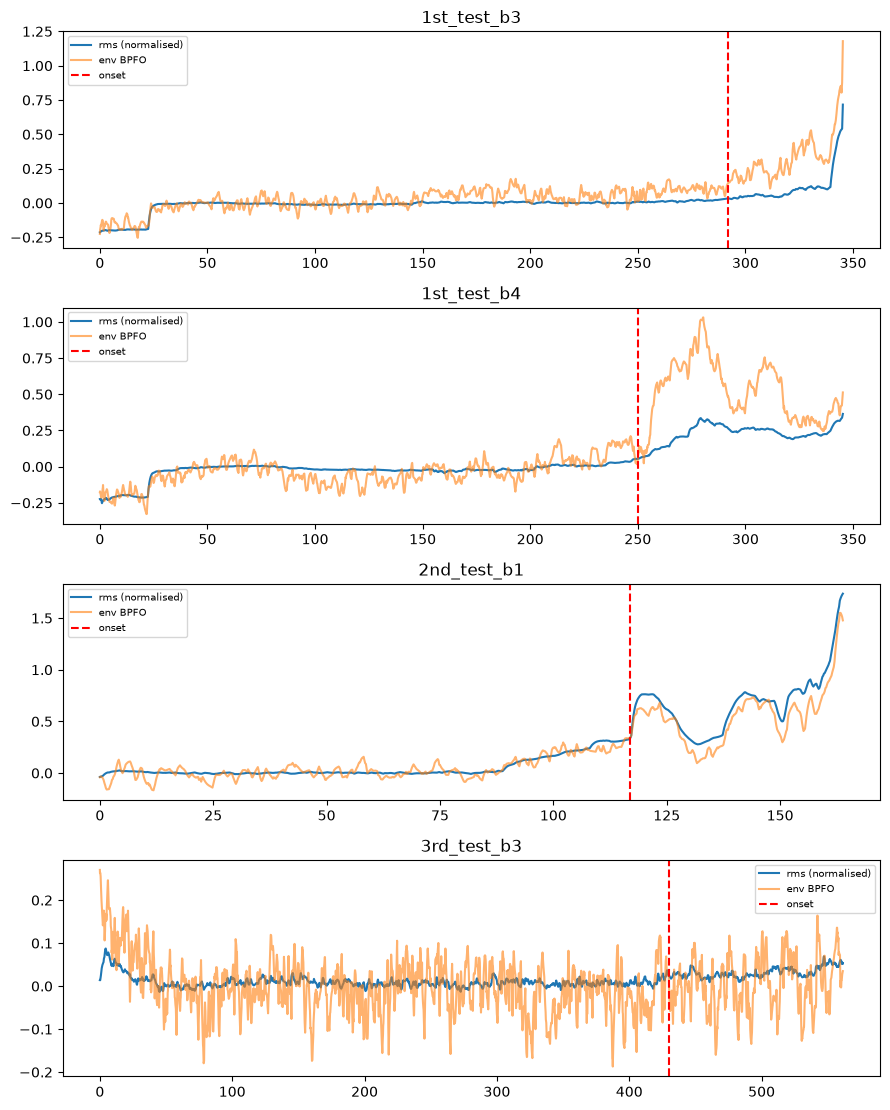

In [10]:
fig, axes = plt.subplots(len(feat.run.unique()), 1, figsize=(9, 2.8*len(feat.run.unique())))
for ax, (run, g) in zip(axes, feat.groupby('run')):
    ax.plot(g['t_hours'], g['rms'], label='rms (normalised)')
    ax.plot(g['t_hours'], g['env_BPFO'], label='env BPFO', alpha=.6)
    ax.axvline(g['onset_hours'].iloc[0], color='r', ls='--', label='onset')
    ax.set_title(run); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [11]:
KEY = ['rms', 'kurt', 'env_BPFO', 'env_BPFI', 'band5', 'band6', 'band7']
feat = feat.sort_values(['run', 'timestamp']).reset_index(drop=True)

for c in KEY:
    warm = feat[c].where(feat['t_hours'] >= 40)               # ignore start-up spike
    feat[c + '_cummax'] = warm.groupby(feat['run']).cummax().fillna(0)
    feat[c + '_roll36'] = feat.groupby('run')[c].transform(lambda s: s.rolling(36, min_periods=1).mean())

X_cols = [c for c in feat.columns
          if c in CORE or c.endswith(('_slope', '_cummax', '_roll36'))]
print(len(X_cols), 'features')

66 features


In [12]:
def make_model(**p):
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300,
                                         l2_regularization=1.0, random_state=0, **p)

WARMUP_H = 40
MONOTONE = True      # run once with False, once with True, and compare tables

def postprocess(pred, t_hours, alpha=0.1, win=25):
    pred = np.asarray(pred); t = np.asarray(t_hours)
    out = np.ones(len(pred)); w = t >= WARMUP_H
    s = pd.Series(pred[w]).rolling(win, min_periods=1).median()   # ignore brief spikes
    s = s.ewm(alpha=alpha, adjust=False).mean().values
    out[w] = np.minimum.accumulate(s) if MONOTONE else s
    return np.clip(out, 0, 1)

def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a)-np.asarray(b))**2)))
def mae(a, b):  return float(np.mean(np.abs(np.asarray(a)-np.asarray(b))))

def predict_run(model, g):
    return postprocess(model.predict(g[X_cols]), g['t_hours'].values)

GRID = [dict(max_depth=d, min_samples_leaf=m) for d in (3, 5) for m in (30, 100)]

In [13]:
tests = list(feat['test'].unique())
results, best_log, preds = [], [], {}

for held in tests:
    rest = feat[feat.test != held]; test = feat[feat.test == held]

    # ---- inner loop: choose hyperparameters on validation ----
    scores = []
    for p in GRID:
        errs = []
        for val_t in rest['test'].unique():
            tr = rest[rest.test != val_t]; va = rest[rest.test == val_t]
            m = make_model(**p).fit(tr[X_cols], tr['target'])
            errs += [rmse(g['target'], predict_run(m, g)) for _, g in va.groupby('run')]
        scores.append(np.mean(errs))
    best = GRID[int(np.argmin(scores))]; best_log.append(best)

    # ---- refit on all non-held data, evaluate ONCE on the held-out test set ----
    m = make_model(**best).fit(rest[X_cols], rest['target'])
    mean_life = rest.groupby('run')['t_hours'].max().mean()
    for run, g in test.groupby('run'):
        pred = predict_run(m, g)
        base = np.clip(1 - g['t_hours'].values/mean_life, 0, 1)   # naive: elapsed time only
        late = g['target'].values < 0.5
        results.append({'test_set': held, 'run': run, 'best_params': best,
                        'RMSE': rmse(g['target'], pred), 'MAE': mae(g['target'], pred),
                        'RMSE_late_half': rmse(g['target'][late], pred[late]),
                        'naive_RMSE': rmse(g['target'], base)})
        preds[run] = (g['t_hours'].values, g['target'].values, pred, base)

res = pd.DataFrame(results)
display(res.round(3))
print(res[['RMSE', 'MAE', 'RMSE_late_half', 'naive_RMSE']].mean().round(3))

,test_set,run,best_params,RMSE,MAE,RMSE_late_half,naive_RMSE
0,1st_test,1st_test_b3,"{'max_depth': 3, 'min_samples_leaf': 100}",0.138,0.049,0.413,0.468
1,1st_test,1st_test_b4,"{'max_depth': 3, 'min_samples_leaf': 100}",0.357,0.301,0.226,0.402
2,2nd_test,2nd_test_b1,"{'max_depth': 3, 'min_samples_leaf': 30}",0.290,0.170,0.254,0.213
3,3rd_test,3rd_test_b3,"{'max_depth': 3, 'min_samples_leaf': 100}",0.276,0.118,0.754,0.711


RMSE              0.265
MAE               0.159
RMSE_late_half    0.412
naive_RMSE        0.448
dtype: float64


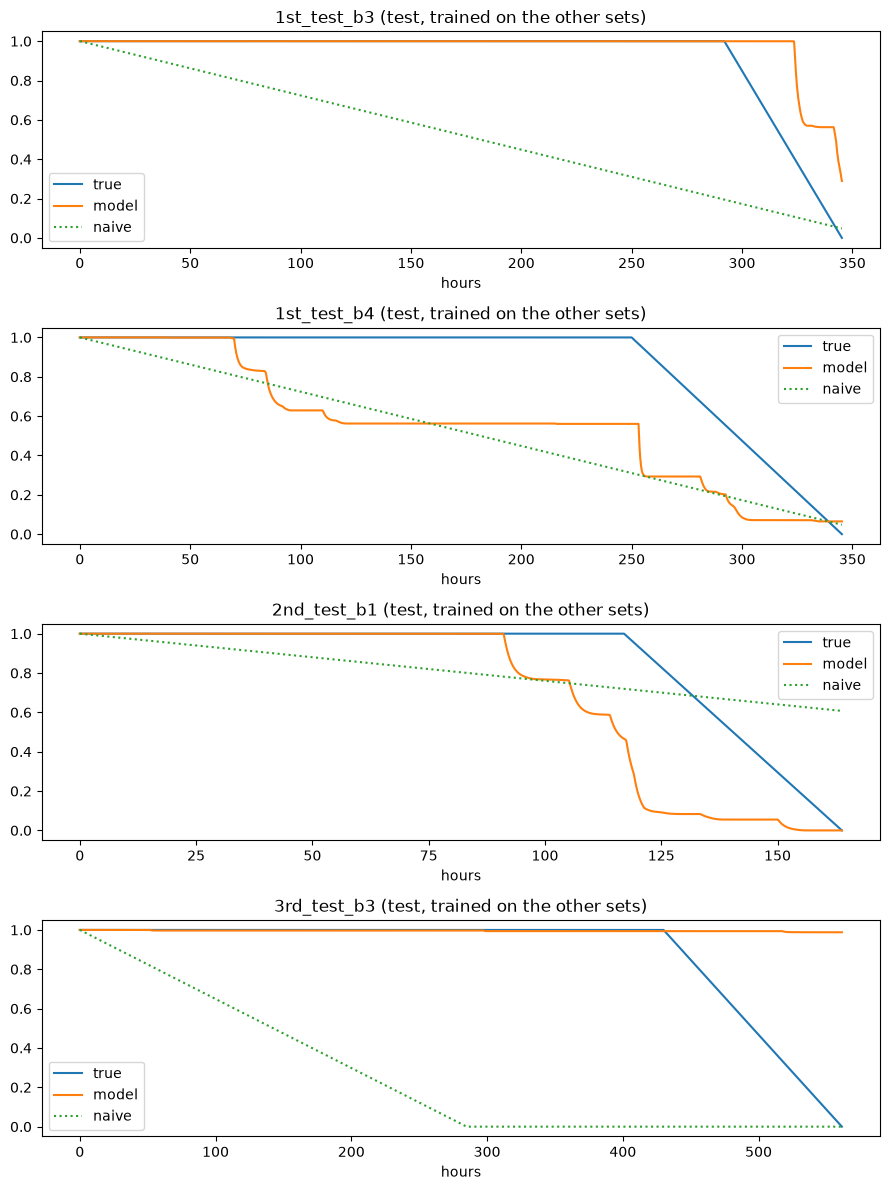

In [14]:
fig, axes = plt.subplots(len(preds), 1, figsize=(9, 3*len(preds)))
for ax, (run, (t, y, p, b)) in zip(np.atleast_1d(axes), preds.items()):
    ax.plot(t, y, label='true'); ax.plot(t, p, label='model'); ax.plot(t, b, ':', label='naive')
    ax.set_title(f'{run} (test, trained on the other sets)'); ax.set_xlabel('hours'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/test_predictions.png', dpi=120); plt.show()

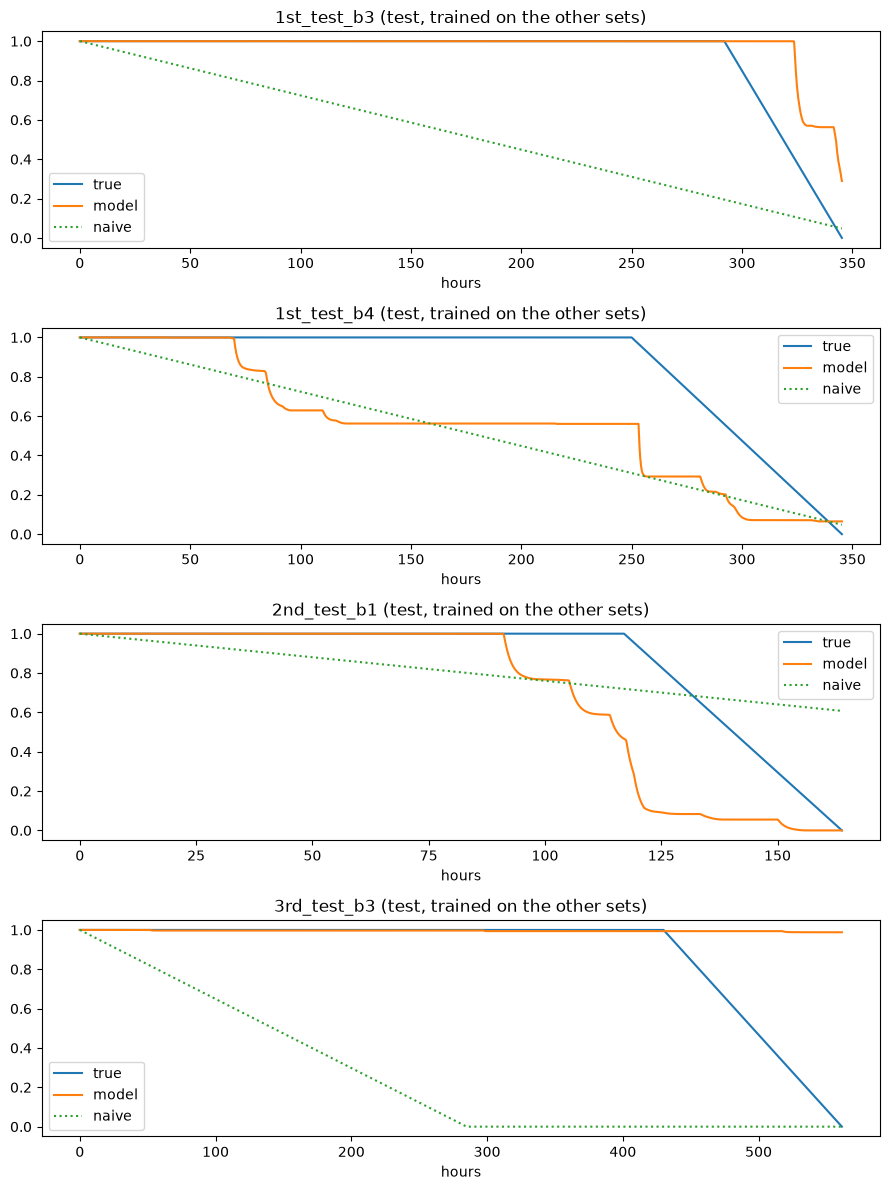

In [15]:
fig, axes = plt.subplots(len(preds), 1, figsize=(9, 3*len(preds)))
for ax, (run, (t, y, p, b)) in zip(np.atleast_1d(axes), preds.items()):
    ax.plot(t, y, label='true'); ax.plot(t, p, label='model'); ax.plot(t, b, ':', label='naive')
    ax.set_title(f'{run} (test, trained on the other sets)'); ax.set_xlabel('hours'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/test_predictions.png', dpi=120); plt.show()

In [16]:
# ===================== EXPERIMENT RUNNER =====================
import time
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

assert TARGET == 'pw', 'set TARGET = "pw" (Cell 3) and rerun Cells 7-8 first'

# ---- reference labels used for SCORING every experiment ----
REF_ONSETS = {'1st_test_b3': 292.0, '1st_test_b4': 250.0,
              '2nd_test_b1': 117.0, '3rd_test_b3': 430.0}
ONSET_SETS = {'ref': REF_ONSETS,
              'b1_95': {**REF_ONSETS, '2nd_test_b1': 95.0},
              'auto': {}}                      # script's own detector, no manual values

# ---- feature groups ----
KEY  = ['rms','kurt','env_BPFO','env_BPFI','band5','band6','band7']
TIME = ['rms','kurt','p2p','crest','std','skew','impulse','margin','peak','mean'] 
TIME = [c for c in TIME if c in CORE]
FREQ = ['centroid','spec_std'] + [f'band{i}' for i in range(8)]
RAW  = [f'raw_{k}' for k in FAULT_HZ]
ENV  = [f'env_{k}' for k in FAULT_HZ]
FSETS = {'all': CORE, 'time': TIME, 'freq': FREQ, 'fault': RAW + ENV, 'env': ENV, 'key7': KEY}

# ---- models ----
MODELS = {
    'hgb_d3_l100': lambda: make_model(max_depth=3, min_samples_leaf=100),
    'hgb_d5_l100': lambda: make_model(max_depth=5, min_samples_leaf=100),
    'hgb_d3_l30':  lambda: make_model(max_depth=3, min_samples_leaf=30),
    'rf':    lambda: RandomForestRegressor(n_estimators=200, min_samples_leaf=50, max_features=0.5, n_jobs=-1, random_state=0),
    'et':    lambda: ExtraTreesRegressor(n_estimators=200, min_samples_leaf=50, max_features=0.5, n_jobs=-1, random_state=0),
    'ridge': lambda: make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
}

# ---- post-processing variants (applied to raw predictions) ----
POST = {
    'none':       dict(warm=40, mono=False, win=1,  alpha=1.0),
    'mono_only':  dict(warm=40, mono=True,  win=1,  alpha=0.1),
    'mono_med25': dict(warm=40, mono=True,  win=25, alpha=0.1),
    'mono_med51': dict(warm=40, mono=True,  win=51, alpha=0.1),
    'med25_free': dict(warm=40, mono=False, win=25, alpha=0.1),
}

def postprocess2(pred, t, warm, mono, win, alpha):
    pred = np.asarray(pred); t = np.asarray(t)
    out = np.ones(len(pred)); w = t >= warm
    s = pd.Series(pred[w])
    if win > 1:     s = s.rolling(win, min_periods=1).median()
    if alpha < 1.0: s = s.ewm(alpha=alpha, adjust=False).mean()
    s = s.values
    out[w] = np.minimum.accumulate(s) if mono else s
    return np.clip(out, 0, 1)

# ---- building blocks ----
_feat_cache = {}
def make_feat(onsets_key, base):
    key = (onsets_key, base)
    if key not in _feat_cache:
        global ONSET_OVERRIDE_HOURS, BASE_START_H, BASE_LEN_H
        old = (ONSET_OVERRIDE_HOURS, BASE_START_H, BASE_LEN_H)
        ONSET_OVERRIDE_HOURS = ONSET_SETS[onsets_key]; BASE_START_H, BASE_LEN_H = base
        try:
            f = build_features(lab).sort_values(['run', 'timestamp']).reset_index(drop=True)
        finally:
            ONSET_OVERRIDE_HOURS, BASE_START_H, BASE_LEN_H = old
        _feat_cache[key] = f
    return _feat_cache[key]

def add_hist(f):
    f = f.copy()
    for c in KEY:
        warm = f[c].where(f['t_hours'] >= 40)
        f[c + '_cummax'] = warm.groupby(f['run']).cummax().fillna(0)
        f[c + '_roll36'] = f.groupby('run')[c].transform(lambda s: s.rolling(36, min_periods=1).mean())
    return f

_ref = make_feat('ref', (40, 30)).set_index(['run', 'timestamp'])['target']

def get_cols(cfg):
    cols = list(FSETS[cfg['feats']])
    if cfg['slope']: cols += [c + '_slope' for c in FSETS[cfg['feats']]]
    if cfg['hist']:  cols += [c + s for c in KEY for s in ('_cummax', '_roll36')]
    return cols

def run_config(cfg):
    f = make_feat(cfg['onsets'], cfg['base'])
    if cfg['hist']: f = add_hist(f)
    cols = get_cols(cfg)
    f = f.assign(y_ref=_ref.reindex(pd.MultiIndex.from_frame(f[['run', 'timestamp']])).values)
    raw = {}
    for held in f['test'].unique():                       # leave-one-test-set-out
        tr, te = f[f.test != held], f[f.test == held]
        m = MODELS[cfg['model']]().fit(tr[cols], tr['target'])
        for run, g in te.groupby('run'):
            raw[run] = (g['t_hours'].values, g['y_ref'].values, m.predict(g[cols]))
    return raw

def metrics(t, y, p, warm=40):
    n = len(t); late = y < 0.5
    healthy = (y >= 1.0) & (t >= warm)
    last = np.arange(n) >= int(0.9 * n)
    t_on = t[y < 1.0][0]
    below = np.where(p < 0.5)[0]
    return dict(RMSE=float(np.sqrt(np.mean((p - y) ** 2))),
                MAE=float(np.mean(np.abs(p - y))),
                RMSE_late=float(np.sqrt(np.mean((p[late] - y[late]) ** 2))),
                false_alarm=float(np.mean(p[healthy] < 0.9)),
                end10=float(p[last].mean()),
                lag_h=float(t[below[0]] - t_on) if len(below) else np.nan)

# ---- ROUND 2 EXPERIMENTS (replaces the DEFINE EXPERIMENTS block) ----
FSETS['freq_fault'] = FREQ + RAW + ENV
FSETS['freq_rk']    = FREQ + ['rms', 'kurt']
FSETS['freq_key']   = list(dict.fromkeys(FREQ + KEY))

def _et(leaf=50, mf=0.5, n=200):
    return lambda: ExtraTreesRegressor(n_estimators=n, min_samples_leaf=leaf, max_features=mf, n_jobs=-1, random_state=0)
MODELS.update({'et_l20': _et(leaf=20), 'et_l100': _et(leaf=100), 'et_mf03': _et(mf=0.3),
               'et_mf10': _et(mf=1.0), 'et_n500': _et(n=500)})

BASE = dict(onsets='ref', base=(40, 30), feats='all', slope=True, hist=False, model='et')
BASE_POST = 'mono_med25'
EXPERIMENTS = []
def add(name, post=None, **kw):
    EXPERIMENTS.append((name, {**BASE, **kw}, post or BASE_POST))

add('ET_BASE')
for fs in ['freq', 'key7', 'fault', 'freq_fault', 'freq_rk', 'freq_key']: add(f'et feats={fs}', feats=fs)
for m in ['et_l20', 'et_l100', 'et_mf03', 'et_mf10', 'et_n500']: add(f'model={m}', model=m)
add('et freq + leaf20', feats='freq', model='et_l20')
add('rf feats=freq', feats='freq', model='rf')
add('et baseline(20,30)', base=(20, 30))
add('et no_slope', slope=False)
add('et onsets=auto', onsets='auto')
for p in ['none', 'mono_only', 'mono_med51']: add(f'et post={p}', post=p)
# add your own combinations here, e.g.:
# add('combo1', onsets='b1_95', model='rf', feats='env')

# ---- RUN ----
raw_cache, rows, errors = {}, [], []
t0 = time.time()
for name, cfg, post in EXPERIMENTS:
    try:
        key = tuple(sorted((k, str(v)) for k, v in cfg.items()))
        if key not in raw_cache: raw_cache[key] = run_config(cfg)
        for run, (t, y, p) in raw_cache[key].items():
            rows.append({'experiment': name, 'run': run, **metrics(t, y, postprocess2(p, t, **POST[post]))})
    except Exception as e:
        errors.append((name, repr(e)))
print(f'done in {time.time()-t0:.0f}s, {len(EXPERIMENTS)} experiments, {len(errors)} errors')

# ---- RESULTS ----
res = pd.DataFrame(rows)
summ = res.groupby('experiment', sort=False).agg(
    RMSE=('RMSE', 'mean'), MAE=('MAE', 'mean'), RMSE_late=('RMSE_late', 'mean'),
    false_alarm=('false_alarm', 'mean'), end10=('end10', 'mean'),
    lag_h=('lag_h', 'mean'), detected=('lag_h', lambda s: int(s.notna().sum())))
summ = summ.join(res[res.run != '3rd_test_b3'].groupby('experiment')['RMSE'].mean().rename('RMSE_ex3rd'))
summ = summ.join(res.pivot(index='experiment', columns='run', values='RMSE').add_prefix('RMSE_'))
summ = summ.sort_values('RMSE')

pd.set_option('display.width', 300); pd.set_option('display.max_columns', 50)
print('\n=== SUMMARY (sorted by mean RMSE; baseline row is "BASELINE") ===')
print(summ.round(3).to_string())
print('\n=== EXPERIMENT SETTINGS ===')
print(pd.DataFrame([{'experiment': n, **c, 'post': p} for n, c, p in EXPERIMENTS]).to_string(index=False))
if errors: print('\n=== ERRORS ===', *errors, sep='\n')

summ.round(4).to_csv(f'{OUT_DIR}/experiment_summary.csv')
res.round(4).to_csv(f'{OUT_DIR}/experiment_per_run.csv', index=False)

done in 73s, 20 experiments, 0 errors

=== SUMMARY (sorted by mean RMSE; baseline row is "BASELINE") ===
                      RMSE    MAE  RMSE_late  false_alarm  end10   lag_h  detected  RMSE_ex3rd  RMSE_1st_test_b3  RMSE_1st_test_b4  RMSE_2nd_test_b1  RMSE_3rd_test_b3
experiment                                                                                                                                                            
et onsets=auto       0.176  0.083      0.404        0.077  0.625  27.493         3       0.144             0.159             0.102             0.170             0.274
et feats=fault       0.178  0.122      0.411        0.361  0.637  37.104         3       0.152             0.135             0.180             0.142             0.257
model=et_mf03        0.180  0.097      0.408        0.097  0.634  27.715         3       0.149             0.142             0.130             0.176             0.270
et feats=freq_fault  0.181  0.102      0.389        0.273  0

In [17]:
r3 = (res[res.run != '3rd_test_b3'].groupby('experiment', sort=False)
      [['RMSE', 'RMSE_late', 'false_alarm', 'end10', 'lag_h']].mean().add_suffix('_3runs')
      .sort_values('RMSE_3runs'))
print(r3.round(3).to_string())

                     RMSE_3runs  RMSE_late_3runs  false_alarm_3runs  end10_3runs  lag_h_3runs
experiment                                                                                   
et onsets=auto            0.144            0.289              0.102        0.505       27.493
model=et_mf03             0.149            0.298              0.130        0.520       27.715
et post=mono_med51        0.150            0.287              0.117        0.506       15.867
et feats=freq_fault       0.151            0.271              0.364        0.493       27.048
et feats=fault            0.152            0.314              0.481        0.538       37.104
et feats=freq_key         0.154            0.305              0.366        0.527       27.826
model=et_n500             0.156            0.267              0.368        0.483       26.660
et post=none              0.156            0.260              0.155        0.484       23.215
model=et_l100             0.156            0.318            

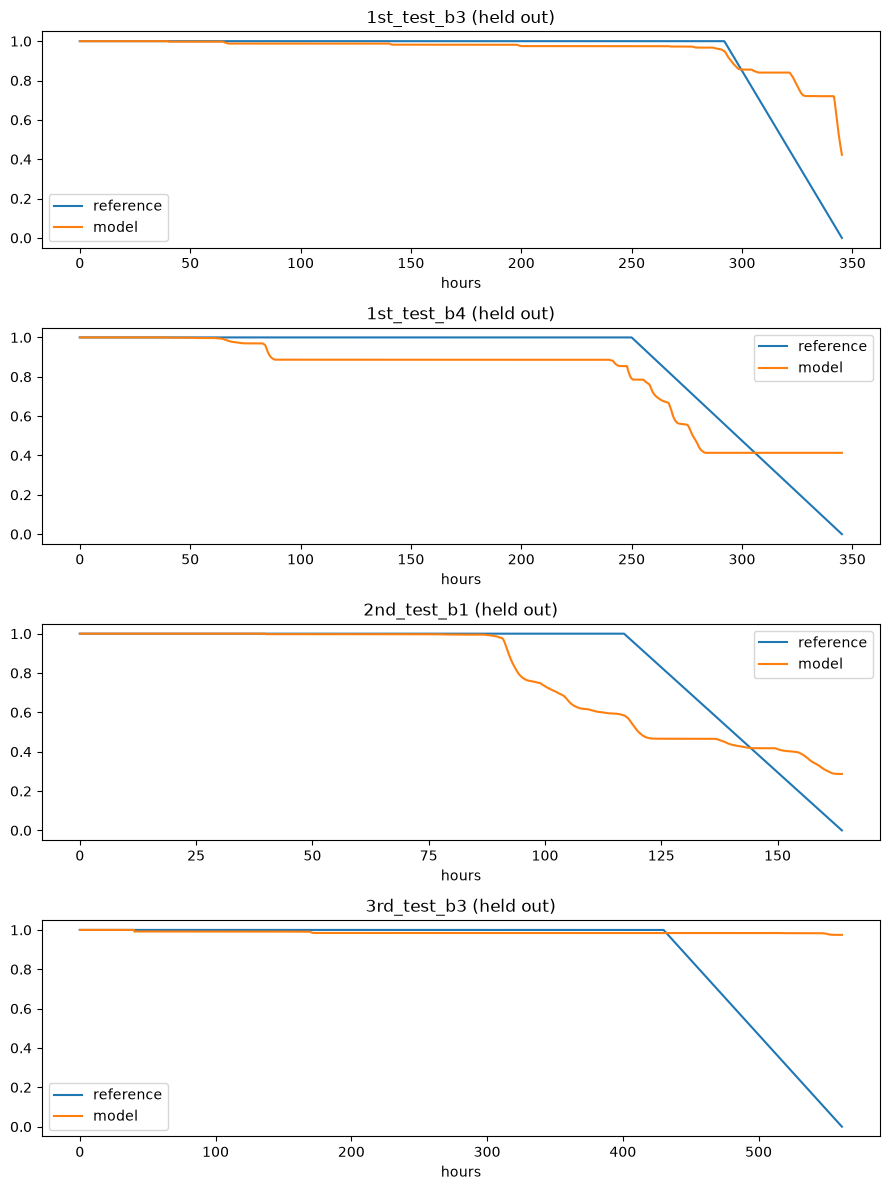

              RMSE    MAE  RMSE_late  false_alarm  end10   lag_h
run                                                             
1st_test_b3  0.141  0.059      0.485        0.000  0.754  52.245
1st_test_b4  0.134  0.107      0.219        0.782  0.413  27.734
2nd_test_b1  0.182  0.109      0.166        0.322  0.363   3.000
3rd_test_b3  0.272  0.122      0.746        0.000  0.982     NaN
RMSE            0.182
MAE             0.099
RMSE_late       0.404
false_alarm     0.276
end10           0.628
lag_h          27.660
dtype: float64
saved C:\Users\Samyuktha K\projects\ML project\bearings_out/rul_model_final.joblib
run
1st_test_b3    292.6
1st_test_b4    244.3
2nd_test_b1    115.3
3rd_test_b3    548.7
Name: onset_hours, dtype: float64


In [18]:
# ===================== FINAL CONFIG: evaluate, plot, train, save =====================
MODELS['et_final'] = lambda: ExtraTreesRegressor(n_estimators=500, min_samples_leaf=50,
                                                 max_features=0.3, n_jobs=-1, random_state=0)
FINAL_CFG  = dict(onsets='ref', base=(40, 30), feats='all', slope=True, hist=False, model='et_final')
FINAL_POST = 'mono_med25'

# 1) held-out evaluation (leave-one-test-set-out), same as the experiments
raw = run_config(FINAL_CFG)
rows = []
fig, axes = plt.subplots(len(raw), 1, figsize=(9, 3 * len(raw)))
for ax, (run, (t, y, p)) in zip(np.atleast_1d(axes), raw.items()):
    pp = postprocess2(p, t, **POST[FINAL_POST])
    rows.append({'run': run, **metrics(t, y, pp)})
    ax.plot(t, y, label='reference'); ax.plot(t, pp, label='model')
    ax.set_title(f'{run} (held out)'); ax.set_xlabel('hours'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/final_heldout.png', dpi=120); plt.show()
final_tbl = pd.DataFrame(rows).set_index('run')
print(final_tbl.round(3)); print(final_tbl.mean().round(3))

# 2) train on all four runs and save
f_all = make_feat(FINAL_CFG['onsets'], FINAL_CFG['base'])
cols = get_cols(FINAL_CFG)
final_model = MODELS[FINAL_CFG['model']]().fit(f_all[cols], f_all['target'])
joblib.dump({'model': final_model, 'cols': cols, 'post': POST[FINAL_POST],
             'baseline_hours': FINAL_CFG['base'], 'cfg': FINAL_CFG},
            f'{OUT_DIR}/rul_model_final.joblib')
print('saved', f'{OUT_DIR}/rul_model_final.joblib')

# 3) for the record: which onsets did the automatic detector pick? (for reproducibility)
print(make_feat('auto', (40, 30)).groupby('run')['onset_hours'].first().round(1))

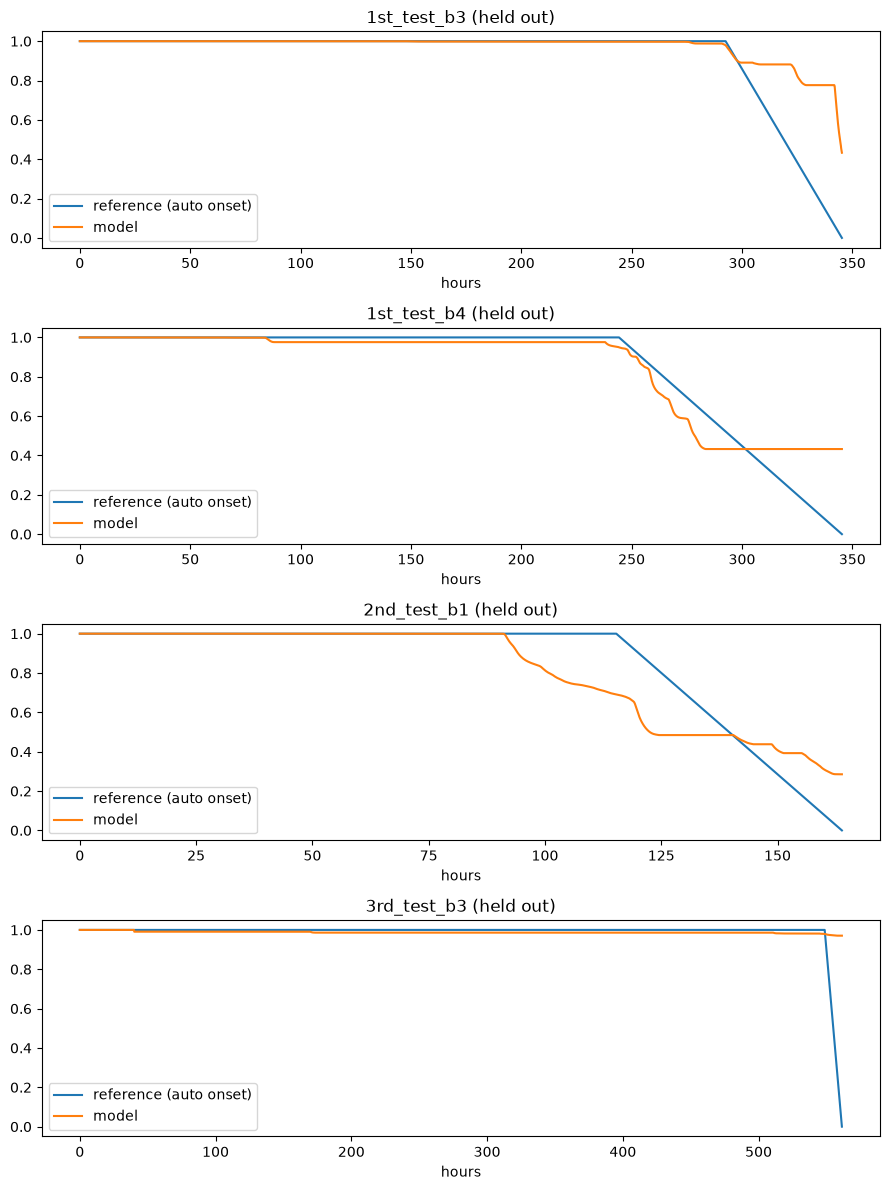

              RMSE    MAE  RMSE_late  false_alarm  end10   lag_h
run                                                             
1st_test_b3  0.155  0.052      0.534         0.00  0.803  51.745
1st_test_b4  0.099  0.053      0.233         0.00  0.433  34.291
2nd_test_b1  0.142  0.085      0.168         0.28  0.363   7.167
3rd_test_b3  0.085  0.022      0.736         0.00  0.980     NaN
RMSE            0.120
MAE             0.053
RMSE_late       0.418
false_alarm     0.070
end10           0.645
lag_h          31.068
dtype: float64
saved rul_model_final_v2.joblib


In [19]:
# ===================== FINAL v2: use auto-detected onsets for labels AND scoring =====================
_ref = make_feat('auto', (40, 30)).set_index(['run', 'timestamp'])['target']   # new scoring reference
FINAL_CFG = dict(onsets='auto', base=(40, 30), feats='all', slope=True, hist=False, model='et_final')

raw = run_config(FINAL_CFG)
rows = []
fig, axes = plt.subplots(len(raw), 1, figsize=(9, 3 * len(raw)))
for ax, (run, (t, y, p)) in zip(np.atleast_1d(axes), raw.items()):
    pp = postprocess2(p, t, **POST[FINAL_POST])
    rows.append({'run': run, **metrics(t, y, pp)})
    ax.plot(t, y, label='reference (auto onset)'); ax.plot(t, pp, label='model')
    ax.set_title(f'{run} (held out)'); ax.set_xlabel('hours'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/final_v2_heldout.png', dpi=120); plt.show()
tbl = pd.DataFrame(rows).set_index('run'); print(tbl.round(3)); print(tbl.mean().round(3))

f_all = make_feat('auto', (40, 30)); cols = get_cols(FINAL_CFG)
final_model = MODELS[FINAL_CFG['model']]().fit(f_all[cols], f_all['target'])
joblib.dump({'model': final_model, 'cols': cols, 'post': POST[FINAL_POST],
             'baseline_hours': FINAL_CFG['base'], 'cfg': FINAL_CFG},
            f'{OUT_DIR}/rul_model_final_v2.joblib')
print('saved rul_model_final_v2.joblib')

Status: CRITICAL
Monitored: 163.8 operating hours (984 snapshots)
Degradation onset detected at: 115.3 h
Model health index: 0.20  (1 = healthy, 0 = failure)
Very rough remaining life: 2-19 h  (uncertain; see warnings)
Strongest fault-frequency evidence: BPFO (outer race), +304% vs baseline

! Model trained on 4 run-to-failure tests from one rig (2000 RPM, 6000 lb); not validated on other bearings, speeds or sensors.
! Near failure the model tends to OVERESTIMATE remaining life; treat 'critical' as urgent.
! Remaining-hours range assumes a degradation stage of 12-95 h, the spread seen in 4 runs; it is very rough.
! Some features were non-positive; z-score normalisation was used for them.
features match:    True
predictions match: True


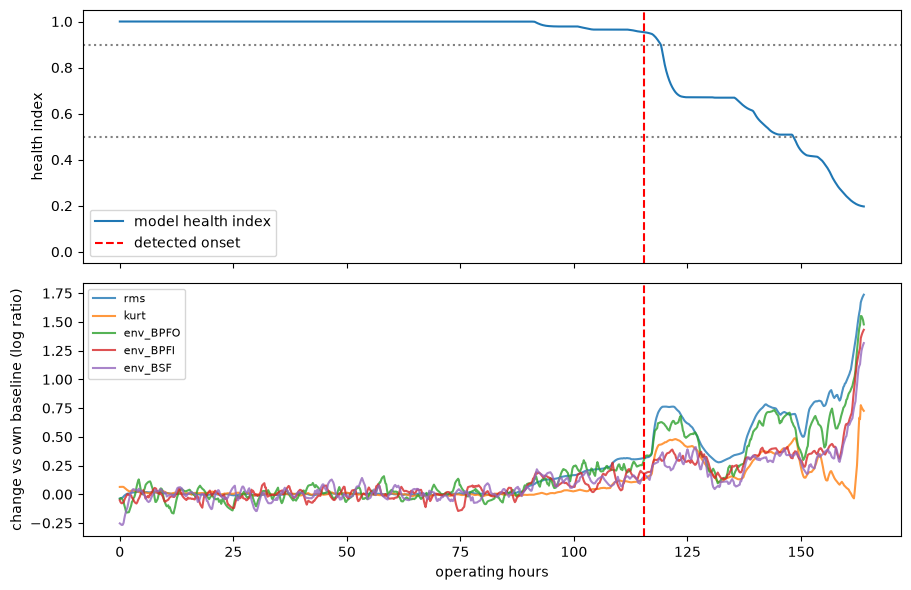

In [20]:
import importlib, bearing_predictor
importlib.reload(bearing_predictor)
from bearing_predictor import BearingRULPredictor

pred = BearingRULPredictor(f'{OUT_DIR}/rul_model_final_v2.joblib')
res = pred.predict(folder=f'{DATA_ROOT}/2nd_test', channels=[0], n_jobs=-1)
print(res.summary())
res.plot()

# --- consistency check against the notebook pipeline ---
f_all = make_feat('auto', (40, 30))
g = f_all[f_all.run == '2nd_test_b1'].sort_values('timestamp')
cols = pred.cols
print('features match:   ', np.allclose(res.features[cols].values, g[cols].values, atol=1e-6))
ref = postprocess2(final_model.predict(g[cols]), g['t_hours'].values, **POST['mono_med25'])
print('predictions match:', np.allclose(res.timeline['rul_fraction'].values, ref, atol=1e-6))

In [21]:
tests = {
    '1st_test b3 (expect inner race, BPFI)': ('1st_test', [4, 5]),
    '1st_test b4 (expect roller, BSF)':      ('1st_test', [6, 7]),
    '2nd_test b2 (expect healthy)':          ('2nd_test', [1]),
    '2nd_test b3 (expect healthy)':          ('2nd_test', [2]),
    # '3rd_test b3 (expect outer race, BPFO)': ('3rd_test', [2]),   # 4,448 files: slow, run last
}
results = {}
for name, (folder, ch) in tests.items():
    r = pred.predict(folder=f'{DATA_ROOT}/{folder}', channels=ch, n_jobs=-1)
    results[name] = r
    ev = {k: round(v['change_pct']) for k, v in r.fault_evidence.items()}
    print(f'{name}\n  status={r.status}  index={r.rul_fraction:.2f}  onset={r.onset_hours}  '
          f'dominant={r.dominant_fault}  evidence(%)={ev}\n')

1st_test b3 (expect inner race, BPFI)
  status=critical  index=0.31  onset=292.5775  dominant=BPFI  evidence(%)={'BPFO': 140, 'BPFI': 369, 'BSF': 142, 'FTF': 120}

1st_test b4 (expect roller, BSF)
  status=critical  index=0.16  onset=244.2861111111111  dominant=BPFI  evidence(%)={'BPFO': 52, 'BPFI': 122, 'BSF': 64, 'FTF': 36}

2nd_test b2 (expect healthy)
  status=degrading  index=0.71  onset=163.0  dominant=BPFI  evidence(%)={'BPFO': 38, 'BPFI': 35, 'BSF': 20, 'FTF': -2}

2nd_test b3 (expect healthy)
  status=degrading  index=0.82  onset=149.83333333333334  dominant=None  evidence(%)={'BPFO': 13, 'BPFI': 1, 'BSF': 0, 'FTF': -11}



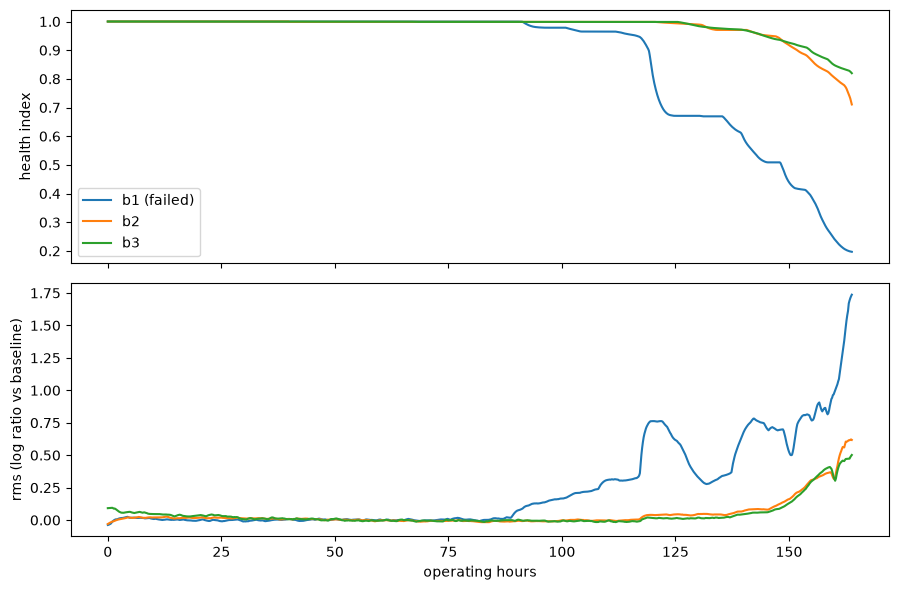

In [22]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for name, r in [('b1 (failed)', res),
                ('b2', results['2nd_test b2 (expect healthy)']),
                ('b3', results['2nd_test b3 (expect healthy)'])]:
    ax[0].plot(r.timeline['t_hours'], r.timeline['rul_fraction'], label=name)
    ax[1].plot(r.timeline['t_hours'], r.timeline['rms'], label=name)
ax[0].set_ylabel('health index'); ax[1].set_ylabel('rms (log ratio vs baseline)')
ax[1].set_xlabel('operating hours'); ax[0].legend(); plt.tight_layout(); plt.show()

===== 2nd_test =====
           status  health_index  onset_h  hours
bearing                                        
b1       critical         0.197    115.3  163.8
b2       elevated         0.711    163.0  163.8
b3       elevated         0.820    149.8  163.8
b4       elevated         0.527    118.0  163.8

* Most affected bearing: 'b1' (health index 0.20, critical).
* 'b2': flagged elevated, but may be influenced by 'b1'.
* 'b3': flagged elevated, but may be influenced by 'b1'.
* 'b4': flagged elevated, but may be influenced by 'b1'. 

===== 1st_test =====
           status  health_index  onset_h  hours
bearing                                        
b1       elevated         0.738     84.5  345.3
b2       elevated         0.756    342.0  345.3
b3       critical         0.310    292.6  345.3
b4       critical         0.158    244.3  345.3

* Most affected bearing: 'b4' (health index 0.16, critical).
* 'b1': flagged elevated, but may be influenced by 'b4'.
* 'b2': flagged elevated, bu

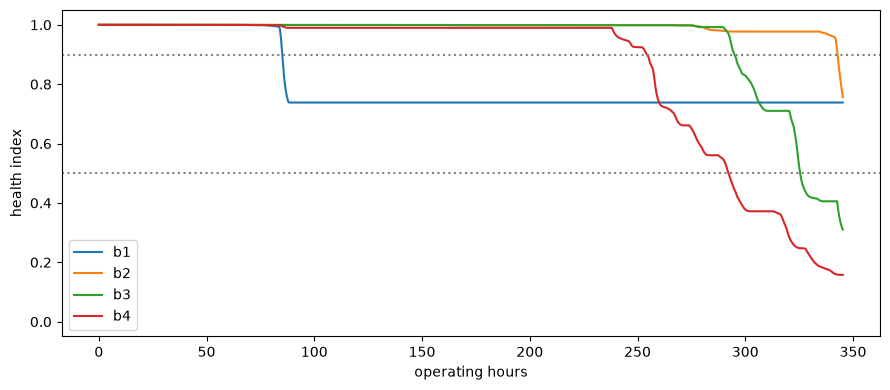

In [27]:
import importlib, bearing_predictor2
importlib.reload(bearing_predictor2)
from bearing_predictor2 import BearingRULPredictor
pred = BearingRULPredictor(f'{OUT_DIR}/rul_model_final_v2.joblib')

machines = {
    '2nd_test': {'b1': [0], 'b2': [1], 'b3': [2], 'b4': [3]},
    '1st_test': {'b1': [0, 1], 'b2': [2, 3], 'b3': [4, 5], 'b4': [6, 7]},
    # '3rd_test': {'b1': [0], 'b2': [1], 'b3': [2], 'b4': [3]},   # slow: run last
}
FAILED = {('1st_test', 'b3'), ('1st_test', 'b4'), ('2nd_test', 'b1'), ('3rd_test', 'b3')}

allres = {}
for folder, bearings in machines.items():
    m = pred.predict_many(bearings, folder=f'{DATA_ROOT}/{folder}', n_jobs=-1)
    allres[folder] = m
    print(f'===== {folder} =====')
    print(m.summary(), '\n')

print('failed-bearing (expected degrading/critical) vs unseen-healthy (expected healthy):')
for folder, m in allres.items():
    for b, r in m.bearings.items():
        kind = 'FAILED ' if (folder, b) in FAILED else 'healthy'
        print(f'{folder} {b} [{kind}]: {r.status:9s} index={r.rul_fraction:.2f}')
m.plot();